# Notebook D — the cascade, end to end

Dialect speech → identification → ASR → cross-dialect translation → speech.

D reads the saved per-utterance outputs of notebooks
B and C, loads the MT model trained in the mBART notebook and measures what
each stage costs the one after it.

## Inputs to attach

| | what | why |
|---|---|---|
| **Notebook Output** | notebook B (identification) | `probs_acoustic.npz` — predicted dialect per clip |
| **Notebook Output** | notebook C (ASR)(V2) | `results/*.json` — the saved transcripts |
| **Notebook Output** | **mBART training notebook** | the MT checkpoint |



## What is measured

There is no parallel target-dialect reference for this test set, so absolute
translation quality is not measurable here. What is measurable is **fidelity**:
how far the pipeline's output drifts from what the same MT model produces given
a perfect transcript and a perfect dialect label.

| | input to MT | isolates |
|---|---|---|
| reference | gold transcript, true label | — |
| oracle | ASR transcript, true label | cost of ASR errors |
| cascade | ASR transcript, **predicted** label | + cost of misidentification |

Reported with chrF alongside BLEU — character-level metrics are more
informative for morphologically rich Bangla, and Bangla word tokenisation is
unreliable.


GPU: On

## D0 — install

**Restart & Clear Cell Outputs after this cell**, then continue from D1.

In [ ]:
!pip uninstall -y torchao 2>&1 | tail -1
!pip install -q sacrebleu gradio 2>&1 | tail -2
import torch, transformers, sacrebleu, platform
print("python", platform.python_version())
print("torch", torch.__version__, "| transformers", transformers.__version__,
      "| sacrebleu", sacrebleu.__version__)
print("gpu", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE")

## D1 — write the scripts

In [1]:
%%writefile /kaggle/working/pipe_common.py
"""Shared pieces for the cascade notebook: paths, the MT wrapper, loaders."""

import os, sys, json, glob
from pathlib import Path

import numpy as np
import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DIALECTS = ["standard", "chittagong", "mymensingh", "barishal", "sylhet", "noakhali"]

RESULTS = Path("/kaggle/working/results"); RESULTS.mkdir(parents=True, exist_ok=True)
OUT = Path("/kaggle/working/cascade"); OUT.mkdir(parents=True, exist_ok=True)


TAG = {"standard": "<bangla>", "chittagong": "<chittagong>",
       "mymensingh": "<mymensingh>", "barishal": "<barishal>",
       "sylhet": "<sylhet>", "noakhali": "<noakhali>"}


def find_mt_models():
    
    found = []
    for cfg in glob.glob("/kaggle/input/**/config.json", recursive=True):
        d = str(Path(cfg).parent)
        try:
            c = json.load(open(cfg))
        except Exception:
            continue
        arch = " ".join(c.get("architectures") or []) + " " + str(c.get("model_type", ""))
        if "mbart" not in arch.lower():
            continue
        if not any(Path(d).glob("*.safetensors")) and not any(Path(d).glob("*.bin")):
            continue          
        found.append(d)

    found.sort(key=lambda d: (("/notebooks/" not in d), ("best" not in d.lower()), d))
    return found


def mt_path():
    p = os.environ.get("MT_MODEL", "").strip()
    if p:
        return p
    hits = find_mt_models()
    if len(hits) > 1:
        print("several MT checkpoints found; using the first:")
        for h in hits:
            print("   ", h)
        print("   (set %env MT_MODEL=<path> to choose another)")
    return hits[0] if hits else ""


class Translator:
    """mBART-50 with dialect tags registered as language codes."""

    def __init__(self, path=None, max_length=96, num_beams=None):
        num_beams = int(os.environ.get("MT_BEAMS", num_beams or 4))
        from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
        path = path or mt_path()
        if not path or not Path(path, "config.json").exists():
            cands = find_mt_models()
            raise SystemExit(
                "MT model not found.\n"
                "Attach the notebook that trained it: + Add Input -> Notebook "
                "Output.\n"
                + ("Candidates seen:\n  " + "\n  ".join(cands) if cands else
                   "Nothing mBART-shaped found under /kaggle/input.")
                + "\nThen set it explicitly:  %env MT_MODEL=<path>")
        print(f"MT model: {path}  (device {DEVICE}, beams {num_beams})")
        self.tok = AutoTokenizer.from_pretrained(path)
        self.model = AutoModelForSeq2SeqLM.from_pretrained(path).to(DEVICE).eval()
        self.tok.src_lang = "bn_IN"
        self.max_length, self.num_beams = max_length, num_beams

        
        self.bos = self.tok.convert_tokens_to_ids("bn_IN")
        self.tag_id = {d: self.tok.convert_tokens_to_ids(t) for d, t in TAG.items()}
        print(f"forced_bos_token_id = {self.bos} (bn_IN)")

    def translate(self, texts, tgt, batch=16):
        """texts: list[str]; tgt: one target dialect for the whole list."""
        out = []
        bos = self.bos
        for i in range(0, len(texts), batch):
            chunk = [t if t.strip() else "." for t in texts[i:i + batch]]
            enc = self.tok(chunk, return_tensors="pt", padding=True,
                           truncation=True, max_length=256).to(DEVICE)
            with torch.no_grad():
                
                g = self.model.generate(**enc, forced_bos_token_id=bos,
                                        max_length=self.max_length,
                                        num_beams=self.num_beams,
                                        no_repeat_ngram_size=3)
            out += self.tok.batch_decode(g, skip_special_tokens=True)
            if (i // batch) % 10 == 0:
                print(f"  MT {min(i + batch, len(texts))}/{len(texts)}")
        return out

    def translate_per_row(self, texts, tgts, batch=16):
        """One target per row. Groups by target so batching still works."""
        out = [None] * len(texts)
        for d in set(tgts):
            idx = [i for i, t in enumerate(tgts) if t == d]
            res = self.translate([texts[i] for i in idx], d, batch)
            for i, r in zip(idx, res):
                out[i] = r
        return out


def load_asr(tag=None):
    """Per-utterance ASR output saved by notebook C."""
    tag = tag or os.environ.get("ASR_RESULT", "whisper_finetuned").strip()
    p = RESULTS / f"{tag}.json"
    if not p.exists():
        raise SystemExit(f"{p} not found -- attach notebook C's output, or set "
                         f"ASR_RESULT to one of: "
                         f"{[Path(x).stem for x in glob.glob(str(RESULTS / '*.json'))]}")
    d = json.load(open(p))
    print(f"ASR source: {tag}  ({len(d['per_clip'])} utterances, "
          f"WER {d['summary']['ALL']['wer']})")
    return d["per_clip"], d


def load_adi(path="/kaggle/working/probs_acoustic.npz"):
    """Predicted dialect per test clip, from notebook B. None if unavailable."""
    p = Path(path)
    if not p.exists():
        cands = glob.glob("/kaggle/input/**/probs_acoustic.npz", recursive=True)
        if not cands:
            print("probs_acoustic.npz not found -- oracle-label results only")
            return None
        p = Path(cands[0])
    z = np.load(p, allow_pickle=True)
    pred = [DIALECTS[i] for i in z["probs"].argmax(1)]
    true = [DIALECTS[i] for i in z["labels"]]
    acc = float(np.mean([a == b for a, b in zip(pred, true)]))
    print(f"ADI source: {p}  ({len(pred)} clips, accuracy {acc:.4f})")
    return {"pred": pred, "true": true, "paths": [str(x) for x in z["paths"]],
            "accuracy": acc}


def bleu(hyps, refs):
    import sacrebleu
    return sacrebleu.corpus_bleu(hyps, [refs], tokenize="char").score


def chrf(hyps, refs):
    import sacrebleu
    return sacrebleu.corpus_chrf(hyps, [refs]).score


Overwriting /kaggle/working/pipe_common.py


In [2]:
%%writefile /kaggle/working/eval_cascade.py
"""Cascade evaluation: what ASR errors and identification errors cost the translation stage."""

import os, sys, json
from pathlib import Path

sys.path.insert(0, "/kaggle/working")
from pipe_common import (Translator, load_asr, load_adi, bleu, chrf,
                         DIALECTS, OUT)

TARGET = os.environ.get("MT_TARGET", "standard").strip()
LIMIT = int(os.environ.get("CASCADE_LIMIT", "0"))    # 0 = all

per_clip, meta = load_asr()
adi = load_adi()
if LIMIT:
    per_clip = per_clip[:LIMIT]
print(f"target dialect: {TARGET}   utterances: {len(per_clip)}")

# ------------------------------------------------------------------ alignment
# The ADI file and the ASR file must describe the same clips in the same order.
if adi is not None:
    if len(adi["pred"]) != len(per_clip):
        print(f"WARNING: ADI has {len(adi['pred'])} clips, ASR has {len(per_clip)}"
              " -- falling back to oracle labels only")
        adi = None
    else:
        mismatch = sum(a != b["dialect"] for a, b in zip(adi["true"], per_clip))
        if mismatch:
            print(f"WARNING: {mismatch} clips disagree on the true dialect between"
                  " the two files -- order differs, using oracle labels only")
            adi = None

gold = [r["ref"] for r in per_clip]
asr = [r["hyp"] for r in per_clip]
true_d = [r["dialect"] for r in per_clip]
pred_d = adi["pred"] if adi else true_d


n_all = len(per_clip)
need_true = [d != TARGET for d in true_d]
need_pred = [d != TARGET for d in pred_d]
routing_errors = sum(a != b for a, b in zip(need_true, need_pred))
print(f"\n{n_all} utterances, {sum(need_true)} genuinely need translation")
print(f"routing decisions that identification got wrong: {routing_errors}"
      f" ({100 * routing_errors / n_all:.1f}%)")

mt = Translator()


def route(texts, do_translate):
    """Translate only the rows flagged for it; pass the rest through."""
    idx = [i for i, t in enumerate(do_translate) if t]
    out = list(texts)
    if idx:
        res = mt.translate([texts[i] for i in idx], TARGET)
        for i, r in zip(idx, res):
            out[i] = r
    return out


print("\n[1/3] reference: gold transcript, true label")
ref = route(gold, need_true)
print("\n[2/3] oracle: ASR transcript, true label")
ora = route(asr, need_true)
if adi and routing_errors:
    print("\n[3/3] cascade: ASR transcript, PREDICTED label")
    cas = route(asr, need_pred)
else:
    cas = ora
    if adi:
        print("\n[3/3] cascade: identical routing to oracle (no routing errors)")

res = {
    "target": TARGET, "n": n_all,
    "n_needing_translation": int(sum(need_true)),
    "asr_source": meta["tag"],
    "asr_wer": meta["summary"]["ALL"]["wer"],
    "adi_accuracy": adi["accuracy"] if adi else None,
    "routing_errors": int(routing_errors),
    "bleu_oracle_vs_reference": round(bleu(ora, ref), 2),
    "chrf_oracle_vs_reference": round(chrf(ora, ref), 2),
    "bleu_cascade_vs_reference": round(bleu(cas, ref), 2),
    "chrf_cascade_vs_reference": round(chrf(cas, ref), 2),
    "mt_is_source_agnostic": True,
}
res["asr_error_gap_bleu"] = round(100.0 - res["bleu_oracle_vs_reference"], 2)
res["misidentification_gap_bleu"] = round(
    res["bleu_oracle_vs_reference"] - res["bleu_cascade_vs_reference"], 2)

print("\n" + "=" * 70)
print("CASCADE FIDELITY  (100 = identical to the gold-transcript pipeline)")
print("=" * 70)
print(f"  ASR system                  {meta['tag']}  (WER {res['asr_wer']})")
print(f"  ADI accuracy                {res['adi_accuracy']}")
print(f"  perfect transcripts         100.00  (definitionally)")
print(f"  + ASR errors                {res['bleu_oracle_vs_reference']:>6} BLEU /"
      f" {res['chrf_oracle_vs_reference']} chrF")
print(f"  + identification errors     {res['bleu_cascade_vs_reference']:>6} BLEU /"
      f" {res['chrf_cascade_vs_reference']} chrF")
print(f"\n  attributable to ASR         {res['asr_error_gap_bleu']} BLEU")
print(f"  attributable to routing     {res['misidentification_gap_bleu']} BLEU"
      f"  ({routing_errors} misrouted utterances)")
print("\n  NOTE: the MT model is source-agnostic (target chosen by "
      "forced_bos_token_id,\n  source always encoded as bn_IN), so the "
      "identification label affects the\n  pipeline only through the decision "
      "of whether to translate at all.")

print(f"\n{'source dialect':<14}{'n':>6}{'BLEU':>9}{'chrF':>9}{'ASR WER':>10}")
per_d = {}
for d in DIALECTS:
    idx = [i for i, x in enumerate(true_d) if x == d]
    if len(idx) < 10:
        continue
    b = round(bleu([cas[i] for i in idx], [ref[i] for i in idx]), 2)
    c = round(chrf([cas[i] for i in idx], [ref[i] for i in idx]), 2)
    w = meta["summary"].get(d, {}).get("wer")
    per_d[d] = {"n": len(idx), "bleu": b, "chrf": c, "asr_wer": w,
                "is_target": d == TARGET}
    star = "  (target: passthrough)" if d == TARGET else ""
    print(f"{d:<14}{len(idx):>6}{b:>9.2f}{c:>9.2f}"
          f"{(w if w is not None else 0):>10.2f}{star}")
res["per_dialect"] = per_d

json.dump(res, open(OUT / f"cascade_{TARGET}.json", "w"), indent=1)
print("\nwrote", OUT / f"cascade_{TARGET}.json")

samples = [{"gold": gold[i], "asr": asr[i], "true_dialect": true_d[i],
            "pred_dialect": pred_d[i], "translated_true_routing": need_true[i],
            "translated_pred_routing": need_pred[i],
            "reference": ref[i], "cascade": cas[i]}
           for i in range(min(25, n_all))]
json.dump(samples, open(OUT / f"samples_{TARGET}.json", "w"),
          ensure_ascii=False, indent=1)
print("wrote", OUT / f"samples_{TARGET}.json")


Overwriting /kaggle/working/eval_cascade.py


In [3]:
%%writefile /kaggle/working/demo_s2st.py
"""End-to-end demonstration: dialect speech in, target-dialect speech out."""

import os, sys, json
from pathlib import Path

sys.path.insert(0, "/kaggle/working")
from pipe_common import Translator, load_asr, load_adi, bleu, DIALECTS, OUT

import numpy as np
import torch
import soundfile as sf

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N = int(os.environ.get("DEMO_N", "12"))
TARGET = os.environ.get("MT_TARGET", "standard").strip()
WAV_DIR = OUT / "audio"; WAV_DIR.mkdir(parents=True, exist_ok=True)


class TTS:
    """MMS-TTS: standard Bangla phonology. See the module docstring."""

    def __init__(self, model_id="facebook/mms-tts-ben"):
        from transformers import VitsModel, AutoTokenizer
        self.tok = AutoTokenizer.from_pretrained(model_id)
        self.model = VitsModel.from_pretrained(model_id).to(DEVICE).eval()
        self.sr = self.model.config.sampling_rate

    def say(self, text, path):
        if not text.strip():
            return None
        enc = self.tok(text, return_tensors="pt").to(DEVICE)
        with torch.no_grad():
            wav = self.model(**enc).waveform[0].cpu().numpy()
        sf.write(str(path), wav, self.sr)
        return str(path)


per_clip, meta = load_asr()
adi = load_adi()
usable = [i for i, r in enumerate(per_clip)
          if r["dialect"] != TARGET and r["hyp"].strip()][:N]
print(f"{len(usable)} demo utterances -> {TARGET}")

mt = Translator()
tts = TTS()
print("TTS sample rate:", tts.sr)

rows = []
texts = [per_clip[i]["hyp"] for i in usable]
trans = mt.translate(texts, TARGET)

for k, i in enumerate(usable):
    r = per_clip[i]
    pred = adi["pred"][i] if adi and len(adi["pred"]) == len(per_clip) else r["dialect"]
    wav = WAV_DIR / f"{k:02d}_{r['dialect']}_to_{TARGET}.wav"
    tts.say(trans[k], wav)
    rows.append({"idx": i, "true_dialect": r["dialect"], "identified_dialect": pred,
                 "id_correct": pred == r["dialect"],
                 "gold_transcript": r["ref"], "asr_transcript": r["hyp"],
                 "translated_text": trans[k], "output_audio": str(wav)})
    print(f"  {k:02d}  {r['dialect']:<12} -> ID {pred:<12} "
          f"{'ok' if pred == r['dialect'] else 'MISS'}")

json.dump(rows, open(OUT / "demo.json", "w"), ensure_ascii=False, indent=1)
print("\nwrote", OUT / "demo.json", "and", len(rows), "wav files in", WAV_DIR)

# ------------------------------------------------------------------ ASR-BLEU
print("\nASR-BLEU: re-transcribing the synthesised audio ...")
try:
    from transformers import WhisperProcessor, WhisperForConditionalGeneration
    MODEL_ID = "ashrafulparan/whisper-small-bangla"
    proc = WhisperProcessor.from_pretrained(MODEL_ID, language="bengali",
                                            task="transcribe")
    m = WhisperForConditionalGeneration.from_pretrained(MODEL_ID).half().cuda().eval()
    m.generation_config.forced_decoder_ids = None
    import librosa
    hyps = []
    for r in rows:
        y, sr = sf.read(r["output_audio"], dtype="float32")
        if sr != 16000:
            y = librosa.resample(y, orig_sr=sr, target_sr=16000)
        f = proc.feature_extractor(y, sampling_rate=16000,
                                   return_tensors="pt").input_features.half().cuda()
        with torch.no_grad():
            g = m.generate(f, max_length=448, language="bengali",
                           task="transcribe", num_beams=5)
        hyps.append(proc.batch_decode(g, skip_special_tokens=True)[0])
    refs = [r["translated_text"] for r in rows]
    s = round(bleu(hyps, refs), 2)
    print(f"ASR-BLEU (chrF-tokenised BLEU): {s}")
    for h, rf in list(zip(hyps, refs))[:3]:
        print(f"\n  synthesised -> {h[:80]}")
        print(f"  intended       {rf[:80]}")
    json.dump({"asr_bleu": s, "n": len(hyps), "hyps": hyps, "refs": refs},
              open(OUT / "asr_bleu.json", "w"), ensure_ascii=False, indent=1)
except Exception as e:
    print("ASR-BLEU skipped:", type(e).__name__, e)

print("\nListen to a sample with:")
print("  import IPython.display as ipd; ipd.Audio(rows[0]['output_audio'])")


Overwriting /kaggle/working/demo_s2st.py


In [4]:
%%writefile /kaggle/working/report_cascade.py
"""Figure + LaTeX table attributing degradation to each cascade stage."""
import sys, json, glob
from pathlib import Path

sys.path.insert(0, "/kaggle/working")
from pipe_common import OUT, DIALECTS

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np

FIG = Path("/kaggle/working/figures"); FIG.mkdir(parents=True, exist_ok=True)

files = sorted(glob.glob(str(OUT / "cascade_*.json")))
if not files:
    raise SystemExit("run eval_cascade.py first")
res = json.load(open(files[0]))
print(json.dumps({k: v for k, v in res.items() if k != "per_dialect"}, indent=1))

# ---------------------------------------------------------------- figure
per = res.get("per_dialect", {})
ds = [d for d in DIALECTS if d in per]
if ds:
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))

    x = np.arange(len(ds))
    b1 = ax[0].bar(x, [per[d]["bleu"] for d in ds], .6, label="BLEU")
    ax[0].bar_label(b1, fmt="%.0f", fontsize=8, padding=1)
    ax[0].set_xticks(x); ax[0].set_xticklabels([d[:9] for d in ds], rotation=20,
                                               ha="right")
    ax[0].set_ylabel("cascade fidelity (BLEU vs gold-transcript output)")
    ax[0].set_title("Translation fidelity by source dialect")

    w = [per[d]["asr_wer"] or 0 for d in ds]
    b = [per[d]["bleu"] for d in ds]
    ax[1].scatter(w, b, s=45)
    for d, xx, yy in zip(ds, w, b):
        ax[1].annotate(d[:9], (xx, yy), fontsize=8,
                       xytext=(4, 3), textcoords="offset points")
    if len(ds) > 2:
        k, c = np.polyfit(w, b, 1)
        xs = np.linspace(min(w), max(w), 20)
        r = np.corrcoef(w, b)[0, 1]
        ax[1].plot(xs, k * xs + c, lw=1, ls="--", alpha=.6,
                   label=f"r = {r:.2f}")
        ax[1].legend(fontsize=8, frameon=False)
    ax[1].set_xlabel("ASR WER (%)"); ax[1].set_ylabel("cascade BLEU")
    ax[1].set_title("Error propagation: ASR quality vs translation fidelity")

    for a in ax:
        a.spines[["top", "right"]].set_visible(False)
        a.grid(axis="y", alpha=.25, lw=.6); a.set_axisbelow(True)
    fig.tight_layout()
    fig.savefig(FIG / "cascade_degradation.png", dpi=160)
    print("wrote", FIG / "cascade_degradation.png")

# ---------------------------------------------------------------- LaTeX
tgt = res["target"]
tex = [r"\begin{table}[t]", r"\centering", r"\small",
       r"\caption{Cascade fidelity into " + tgt + r" Bangla ($n=" +
       f"{res['n']}" + r"$). Scores are against the translation the same model "
       r"produces from the gold transcript with the true dialect label, so "
       r"$100$ denotes an unchanged cascade output rather than perfect "
       r"translation. $^{\dagger}$Target-dialect input, which the router passes "
       r"through untranslated; its score is therefore near $100$ by "
       r"construction and is reported to show the router working, not as "
       r"translation quality.}",
       r"\label{tab:cascade}",
       r"\begin{tabular}{l r r r}", r"\toprule",
       r"Source dialect & ASR WER & BLEU & chrF \\", r"\midrule"]
for d in ds:
    p = per[d]
    w = f"{p['asr_wer']:.1f}" if p.get("asr_wer") is not None else "--"
    note = r"$^{\dagger}$" if p.get("is_target") else ""
    tex.append(f"{d.capitalize()}{note} & {w} & {p['bleu']:.1f} & "
               f"{p['chrf']:.1f} " + r"\\")
tex += [r"\midrule",
        f"Overall & {res['asr_wer']:.1f} & {res['bleu_cascade_vs_reference']:.1f} & "
        f"{res['chrf_cascade_vs_reference']:.1f} " + r"\\",
        r"\bottomrule", r"\end{tabular}", r"\end{table}"]
(OUT / "cascade_table.tex").write_text("\n".join(tex) + "\n")
print("wrote", OUT / "cascade_table.tex")

print("\nstage attribution")


def pick(*keys):
    """Tolerate both the current and the earlier key names."""
    for k in keys:
        if k in res:
            return res[k]
    return None


asr_gap = pick("asr_error_gap_bleu", "cost_of_asr_errors_bleu")
id_gap = pick("misidentification_gap_bleu", "cost_of_misidentification_bleu")
print(f"  cost of ASR errors          {asr_gap} BLEU")
print(f"  cost of misidentification   {id_gap} BLEU"
      + (f"   ({res['routing_errors']} misrouted utterances)"
         if res.get("routing_errors") is not None else ""))
if res.get("adi_accuracy") is None:
    print("  (identification cost unmeasured -- probs_acoustic.npz was missing)")
elif res.get("routing_errors") == 0:
    print("  (identification made no routing errors on this set, so its cost is 0"
          " by measurement, not by assumption)")
if res.get("mt_is_source_agnostic"):
    print("\n  The MT model selects the target with forced_bos_token_id and always"
          "\n  encodes the source as bn_IN, so the identification label reaches the"
          "\n  pipeline only through the decision of whether to translate at all.")

Overwriting /kaggle/working/report_cascade.py


## D2 — collect the upstream outputs and verify

Copies what B and C produced into this session's working directory, lists every
mBART checkpoint it can see, and checks that B's and C's files describe the same
clips in the same order.

In [5]:
import shutil, glob, json, sys
from pathlib import Path

W = Path("/kaggle/working"); (W / "results").mkdir(parents=True, exist_ok=True)
for src in glob.glob("/kaggle/input/**/results/*.json", recursive=True):
    shutil.copy(src, W / "results" / Path(src).name)
for src in glob.glob("/kaggle/input/**/probs_acoustic.npz", recursive=True):
    shutil.copy(src, W / "probs_acoustic.npz")

print("ASR results available:")
for p in sorted(glob.glob(str(W / "results" / "*.json"))):
    d = json.load(open(p))
    if "summary" not in d:
        continue
    s = d["summary"]["ALL"]
    print(f"  {Path(p).stem:<30} WER {s['wer']:>6.2f}  n={s['n']}")

print("\nADI predictions:", (W / "probs_acoustic.npz").exists())

sys.path.insert(0, "/kaggle/working")
from pipe_common import find_mt_models
print("\nmBART checkpoints found:")
for d in find_mt_models():
    print("  ", d)

ASR results available:
  nemo_finetuned                 WER  67.45  n=1387
  nemo_zeroshot                  WER  79.78  n=1387
  whisper_finetuned              WER  54.51  n=1387
  whisper_finetuned_greedy       WER  56.76  n=1387
  whisper_zeroshot               WER  56.52  n=1387
  whisper_zeroshot_greedy        WER  57.96  n=1387

ADI predictions: True

mBART checkpoints found:
   /kaggle/input/notebooks/tasfiaisrat/mbart-qpain/mbart50_best


In [6]:
%env MT_MODEL=
%env ASR_RESULT=whisper_finetuned
%env MT_TARGET=standard

env: MT_MODEL=
env: ASR_RESULT=whisper_finetuned
env: MT_TARGET=standard


# D3 — cascade evaluation

In [7]:
%cd /kaggle/working
%run eval_cascade.py

/kaggle/working
ASR source: whisper_finetuned  (1387 utterances, WER 54.51)
ADI source: /kaggle/working/probs_acoustic.npz  (1387 clips, accuracy 0.9553)
target dialect: standard   utterances: 1387

1387 utterances, 1280 genuinely need translation
routing decisions that identification got wrong: 1 (0.1%)
MT model: /kaggle/input/notebooks/tasfiaisrat/mbart-qpain/mbart50_best  (device cuda, beams 4)


Loading weights:   0%|          | 0/516 [00:00<?, ?it/s]

forced_bos_token_id = 250028 (bn_IN)

[1/3] reference: gold transcript, true label
  MT 16/1280
  MT 176/1280
  MT 336/1280
  MT 496/1280
  MT 656/1280
  MT 816/1280
  MT 976/1280
  MT 1136/1280

[2/3] oracle: ASR transcript, true label
  MT 16/1280
  MT 176/1280
  MT 336/1280
  MT 496/1280
  MT 656/1280
  MT 816/1280
  MT 976/1280
  MT 1136/1280

[3/3] cascade: ASR transcript, PREDICTED label
  MT 16/1279
  MT 176/1279
  MT 336/1279
  MT 496/1279
  MT 656/1279
  MT 816/1279
  MT 976/1279
  MT 1136/1279

CASCADE FIDELITY  (100 = identical to the gold-transcript pipeline)
  ASR system                  whisper_finetuned  (WER 54.51)
  ADI accuracy                0.9552992069214131
  perfect transcripts         100.00  (definitionally)
  + ASR errors                 42.78 BLEU / 37.44 chrF
  + identification errors      42.77 BLEU / 37.44 chrF

  attributable to ASR         57.22 BLEU
  attributable to routing     0.01 BLEU  (1 misrouted utterances)

  NOTE: the MT model is source-agnosti

One structural point, also printed by the cell: the MT model is
**source-agnostic** — it selects the target with `forced_bos_token_id` and
always encodes the source as `bn_IN`. The identification label therefore cannot
change a translation. Where it does act is the routing decision *before* MT:
translate only if the input is not already in the target dialect. A
misidentification either translates target-dialect speech unnecessarily or
leaves dialect speech untranslated, and that is the cost this cell isolates.

# D4 — batch demonstration with audio

Runs the real components on a dozen clips, writes the output speech, and
computes ASR-BLEU: re-transcribe the synthesised audio and compare against the
text fed to the synthesiser. That is the standard proxy for whether the speech
output preserved the content.

In [8]:
%env DEMO_N=12
%cd /kaggle/working
%run demo_s2st.py

env: DEMO_N=12
/kaggle/working
ASR source: whisper_finetuned  (1387 utterances, WER 54.51)
ADI source: /kaggle/working/probs_acoustic.npz  (1387 clips, accuracy 0.9553)
12 demo utterances -> standard
MT model: /kaggle/input/notebooks/tasfiaisrat/mbart-qpain/mbart50_best  (device cuda, beams 4)


Loading weights:   0%|          | 0/516 [00:00<?, ?it/s]

forced_bos_token_id = 250028 (bn_IN)


config.json:   0%|          | 0.00/1.64k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/3.45k [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


ASR-BLEU (chrF-tokenised BLEU): 59.49

  synthesised -> একমাত্র গিয়াও শেষ হইয়া যায়, যা চালায়, তাহিন থাকা থাইক্কা যা চেইল লাগে সে। তারহর 
  intended       একমাত্র গিয়োর শেষ হয়ে যায় যা চালায় তাহীন থাকা থাইক্কা যা চইল্লা গেসে তার হর 

  synthesised -> যেত্তে তুই যেমন কিচ্ছু, আয় কিচ্ছু। যারার মতন জানা আছে, কিন্তু তোমার মতন এখনও বুঝ
  intended       যেত্তে তুই যেমন কইছো আরে কইচ্ছো যারার মতন জানা আছে কিনতু তুমার মতন এখনো বুঝি দেই

  synthesised -> মানে মা ইকশিন বেলে স্টুডেন্টও থাইককা। তার লগে কী কাম করিরা দেতলাম! অনেকদিন হেতার
  intended       মানি মাইকষিন বেলে স্টুডেন্ট থাইক্কা তার লগে কি কাম কইররা দেখলাম অনেক দিন হেতার ল

Listen to a sample with:
  import IPython.display as ipd; ipd.Audio(rows[0]['output_audio'])


In [9]:
import json
import IPython.display as ipd
rows = json.load(open("/kaggle/working/cascade/demo.json"))
r = rows[0]
print("true dialect   :", r["true_dialect"])
print("identified as  :", r["identified_dialect"])
print("ASR transcript :", r["asr_transcript"][:110])
print("translated     :", r["translated_text"][:110])
ipd.Audio(r["output_audio"])

true dialect   : chittagong
identified as  : sylhet
ASR transcript : একমাত্র গ্যাসর গ্যাস দিয়্যে যিয়্যিন চালাই, ইয়্যিন ছাড়া তাইলে দি যিয়্যিন চলের। ইয়্যিন তারফরের তুন ইতে বেয
translated     : একমাত্র গিয়োর শেষ হয়ে যায় যা চালায় তাহীন থাকা থাইক্কা যা চইল্লা গেসে তার হর হে সব ঠিক করি হালাই গেছে একদল 


**Listen to it.** This is where the weakest stage becomes audible:
MMS-TTS models standard Bangla phonology only, so given Sylheti text it produces
a standard-Bangla voice reading Sylheti words. The words are right; the accent
is not the target dialect's. That is a genuine limitation of this version and
should be stated as one — fixing it needs reference-conditioned synthesis, which
is not implemented here.

# D5 — figure and LaTeX table

In [10]:
%cd /kaggle/working
%run report_cascade.py

/kaggle/working
{
 "target": "standard",
 "n": 1387,
 "n_needing_translation": 1280,
 "asr_source": "whisper_finetuned",
 "asr_wer": 54.51,
 "adi_accuracy": 0.9552992069214131,
 "routing_errors": 1,
 "bleu_oracle_vs_reference": 42.78,
 "chrf_oracle_vs_reference": 37.44,
 "bleu_cascade_vs_reference": 42.77,
 "chrf_cascade_vs_reference": 37.44,
 "mt_is_source_agnostic": true,
 "asr_error_gap_bleu": 57.22,
 "misidentification_gap_bleu": 0.01
}
wrote /kaggle/working/figures/cascade_degradation.png
wrote /kaggle/working/cascade/cascade_table.tex

stage attribution
  cost of ASR errors          57.22 BLEU
  cost of misidentification   0.01 BLEU   (1 misrouted utterances)

  The MT model selects the target with forced_bos_token_id and always
  encodes the source as bn_IN, so the identification label reaches the
  pipeline only through the decision of whether to translate at all.


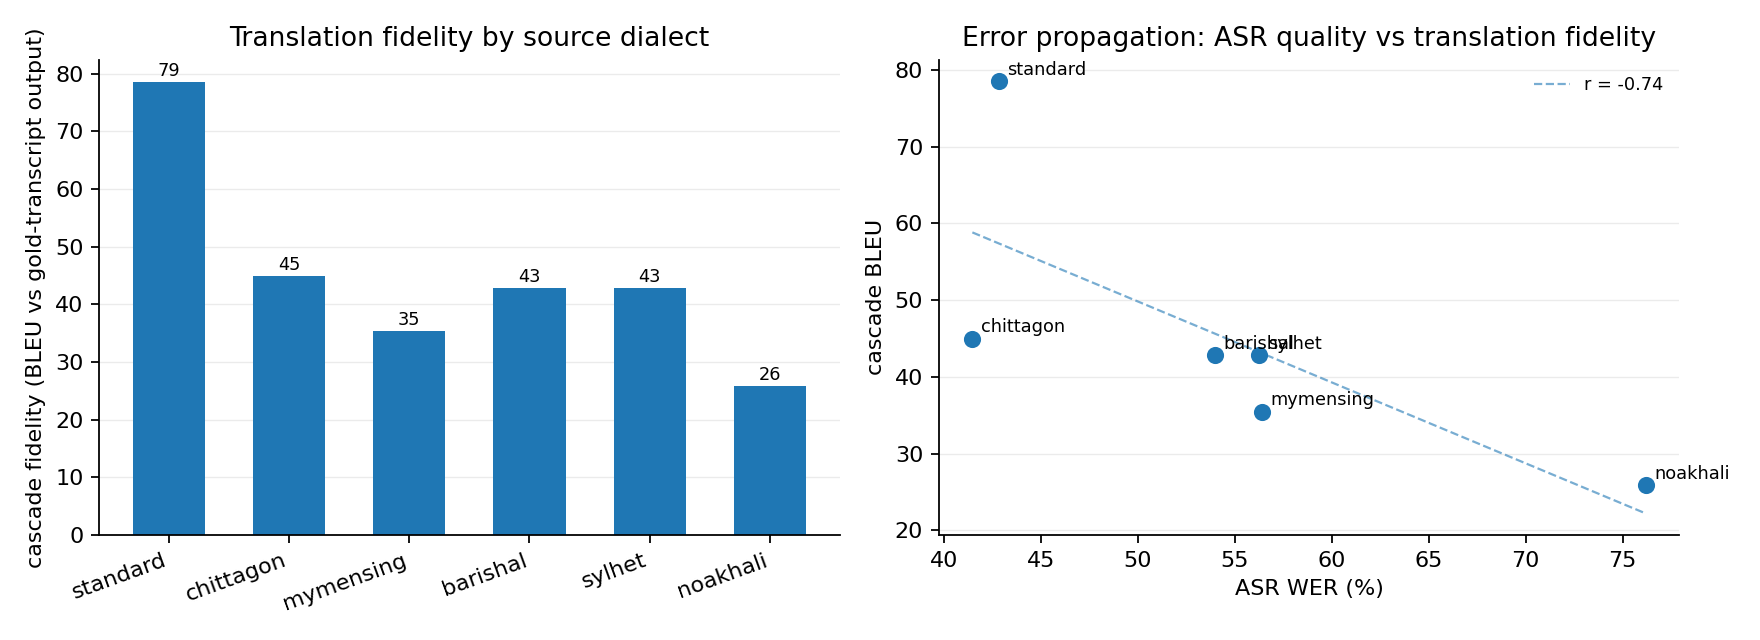

In [11]:
from IPython.display import Image, display
display(Image("/kaggle/working/figures/cascade_degradation.png"))

# D7 — verify, then Save Version

In [12]:
import json, glob, os
from pathlib import Path
C = Path("/kaggle/working/cascade")
print("outputs:")
for p in sorted(glob.glob(str(C / "*.json"))):
    print("  ", Path(p).name)
f = C / "cascade_standard.json"
if f.exists():
    print("\n" + json.dumps({k: v for k, v in json.load(open(f)).items()
                             if k != "per_dialect"}, indent=1))
print("\naudio files:", len(glob.glob(str(C / "audio" / "*.wav"))))
os.system("du -sh /kaggle/working")

outputs:
   asr_bleu.json
   cascade_standard.json
   demo.json
   samples_standard.json

{
 "target": "standard",
 "n": 1387,
 "n_needing_translation": 1280,
 "asr_source": "whisper_finetuned",
 "asr_wer": 54.51,
 "adi_accuracy": 0.9552992069214131,
 "routing_errors": 1,
 "bleu_oracle_vs_reference": 42.78,
 "chrf_oracle_vs_reference": 37.44,
 "bleu_cascade_vs_reference": 42.77,
 "chrf_cascade_vs_reference": 37.44,
 "mt_is_source_agnostic": true,
 "asr_error_gap_bleu": 57.22,
 "misidentification_gap_bleu": 0.01
}

audio files: 12
15M	/kaggle/working


0